# Preprocessing — Dataset Loading, EDA, Cleaning & Feature Engineering
Loads `cv23.sas7bdat`, performs the full EDA and preprocessing pipeline, and saves the final train/test artifacts to `data/processed/model_ready_data.pkl` for use by `regression.ipynb` and `classification.ipynb`.

**Run this notebook first**, before running either track notebook.

In [1]:
pip install sas7bdat

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR, SVC
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                              classification_report)
import time

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", palette="colorblind")
RANDOM_STATE = 42

In [3]:
from sas7bdat import SAS7BDAT

with SAS7BDAT('../data/cv23.sas7bdat') as f:
    df = f.to_data_frame()

print("Shape:", df.shape)
df.dtypes

Shape: (293677, 46)


CIRCUIT     float64
DISTRICT     object
OFFICE       object
DOCKET       object
ORIGIN      float64
FILEDATE     object
FDATEUSE     object
JURIS       float64
NOS         float64
TITL         object
SECTION      object
SUBSECT      object
RESIDENC    float64
JURY         object
CLASSACT    float64
DEMANDED    float64
FILEJUDG     object
FILEMAG      object
COUNTY       object
ARBIT        object
MDLDOCK      object
PLT          object
DEF          object
TRANSDAT     object
TRANSOFF     object
TRANSDOC     object
TRANSORG     object
TERMDATE     object
TDATEUSE     object
TRCLACT     float64
TERMJUDG     object
TERMMAG      object
PROCPROG    float64
DISP        float64
NOJ         float64
AMTREC      float64
JUDGMENT    float64
DJOINED      object
PRETRIAL     object
TRIBEGAN     object
TRIALEND     object
TRMARB       object
PROSE       float64
IFP          object
STATUSCD     object
TAPEYEAR    float64
dtype: object

In [4]:
print("Naive missing-value check:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Naive missing-value check:
TRIBEGAN    292042
TRIALEND    291775
TRANSDAT    288764
PRETRIAL    278137
DJOINED     185853
CIRCUIT          0
FDATEUSE         0
JURIS            0
NOS              0
DISTRICT         0
dtype: int64


# Missing Value Report
df.isnull().sum() only detects actual NaN values. However, this dataset also uses -8 as a missing/not-applicable value in many numeric columns, and some text columns use '-8'.

So, checking only NaN values would make the dataset look almost completely complete. Therefore, we also check for these sentinel values to identify the actual missing data.

In [5]:
def sentinel_missing_report(frame):
    rows = []
    for c in frame.columns:
        col = frame[c]
        if pd.api.types.is_numeric_dtype(col):
            n_sentinel = int((col == -8).sum())
        else:
            n_sentinel = int((col.astype(str) == "-8").sum())
        if n_sentinel > 0:
            rows.append((c, n_sentinel, round(n_sentinel / len(frame) * 100, 1)))
    return pd.DataFrame(rows, columns=["column", "n_sentinel_missing", "pct_sentinel_missing"]) \
             .sort_values("pct_sentinel_missing", ascending=False)

sentinel_report = sentinel_missing_report(df)
sentinel_report

,column,n_sentinel_missing,pct_sentinel_missing
13,TRMARB,291960,99.4
12,TRCLACT,290551,98.9
10,TRANSDOC,288764,98.3
9,TRANSOFF,288764,98.3
11,TRANSORG,288765,98.3
5,ARBIT,284971,97.0
4,CLASSACT,284409,96.8
14,IFP,257435,87.7
6,MDLDOCK,233146,79.4
3,RESIDENC,179832,61.2


**Interpretation:**
| Column | % coded `-8` | What it actually means |
|---|---|---|
| `TRCLACT` | ~99% | Almost no case reaches a class-action certification *ruling* — expected, since it only applies when `CLASSACT == 1`. |
| `CLASSACT` | ~97% | Almost no case is filed as a class action at all — this is a genuinely rare binary event, not "missing data" to impute. |
| `RESIDENC` | ~61% | **Conditionally populated by design** — the codebook states it is used *only when `JURIS == 4`* (diversity jurisdiction). We verify this directly below. |
| `ARBIT` / `TRMARB` | very high | Only ~20 courts participate in the Formal Arbitration Program per the codebook — near-total missingness is expected, not an error. |
| `MDLDOCK` | very high | Only populated for multidistrict-litigation cases — a small subset. |


In [6]:
# Verify RESIDENC missingness is structural, not random: it should be
# populated iff JURIS == 4 (diversity jurisdiction), per the codebook.
match_rate = (df["RESIDENC"].ne(-8) == df["JURIS"].eq(4)).mean() * 100
print(f"RESIDENC populated matches JURIS==4 for {match_rate:.1f}% of rows")

RESIDENC populated matches JURIS==4 for 100.0% of rows


**Target 1 — Regression: RESOLUTION_DAYS**

In [7]:
df["FILEDATE"] = pd.to_datetime(df["FILEDATE"])
df["TERMDATE"] = pd.to_datetime(df["TERMDATE"])
df["RESOLUTION_DAYS"] = (df["TERMDATE"] - df["FILEDATE"]).dt.days
print("Any null TERMDATE (pending cases) in this extract:", df["TERMDATE"].isnull().sum())
print("Any negative durations (data-integrity check):", (df["RESOLUTION_DAYS"] < 0).sum())
df["RESOLUTION_DAYS"].describe()

Any null TERMDATE (pending cases) in this extract: 0
Any negative durations (data-integrity check): 0


count    293677.000000
mean        419.339032
std         492.558613
min           0.000000
25%          77.000000
50%         242.000000
75%         609.000000
max       18915.000000
Name: RESOLUTION_DAYS, dtype: float64

**Interpretation:** We check whether TERMDATE is ever null (which would mean this extract contains pending cases with no resolvable duration) and whether any case shows a negative duration (a filing/termination date data-integrity error). The distribution is strongly right-skewed: the mean sits well above the median, with a long tail of multi-year cases.

In [8]:
disp_map = {
    # Transferred or Remanded
    0: "Transferred", 1: "Transferred", 10: "Transferred", 11: "Transferred",
    # Dismissals (settled pulled out into its own class)
    2: "Dismissed", 3: "Dismissed", 12: "Dismissed", 14: "Dismissed",
    13: "Settled",
    # Judgment On ... (incl. arbitration award, bankruptcy stay, appeal outcomes)
    4: "Judgment", 5: "Judgment", 6: "Judgment", 7: "Judgment", 8: "Judgment",
    9: "Judgment", 15: "Judgment", 16: "Judgment", 17: "Judgment",
    19: "Judgment", 20: "Judgment",
    # Statistical closing
    18: "Statistical",
}
df["CASE_OUTCOME"] = df["DISP"].map(disp_map)

print("Unmapped DISP codes (should be 0):", df["CASE_OUTCOME"].isnull().sum())
df["CASE_OUTCOME"].value_counts(normalize=True).mul(100).round(1)

Unmapped DISP codes (should be 0): 0


CASE_OUTCOME
Dismissed      49.1
Settled        19.7
Judgment       17.2
Transferred     7.0
Statistical     7.0
Name: proportion, dtype: float64

**Grouping NOS:**
Collapse the ~90 raw NOS codes into interpretable buckets, using
    explicit codebook-derived ranges so unrelated code blocks are never
    accidentally merged (e.g. NOS 850 = Securities, kept out of the
    Intellectual Property range 820-840).

In [9]:
def group_nos(code):
    if pd.isna(code):
        return "Other"
    c = int(code)
    if 110 <= c <= 196:
        return "Contract"
    if 310 <= c <= 368:
        return "Torts - Personal Injury"
    if 440 <= c <= 448:
        return "Civil Rights"
    if c in (450, 460, 462, 463, 465):
        return "Immigration"
    if c in (510, 530, 535, 540, 550, 555, 560):
        return "Prisoner Petitions"
    if c in (710, 720, 740, 751, 790, 791):
        return "Labor"
    if c in (820, 830, 835, 840):
        return "Intellectual Property"
    if 861 <= c <= 865:
        return "Social Security"
    return "Other"  # Real Property, Bankruptcy(422/423), RICO(470), Securities(850),
                     # Tax(870s), Consumer Credit(480/485), Forfeiture(625/690), etc.

df["NOS_GROUP"] = df["NOS"].apply(group_nos)
df["NOS_GROUP"].value_counts()

NOS_GROUP
Torts - Personal Injury    85880
Prisoner Petitions         51283
Civil Rights               39846
Other                      35281
Contract                   28904
Social Security            16015
Labor                      13472
Intellectual Property      12709
Immigration                10287
Name: count, dtype: int64

**Interpretation:** All rows should map cleanly to one of the 5 classes (0 unmapped), confirming the DISP codebook was applied correctly. Class balance is moderately imbalanced (Dismissed is the plurality class, with Settled, Judgment, Transferred, and Statistical trailing). This is workable but means plain accuracy would be misleading (a trivial "always predict Dismissed" model would still score well)

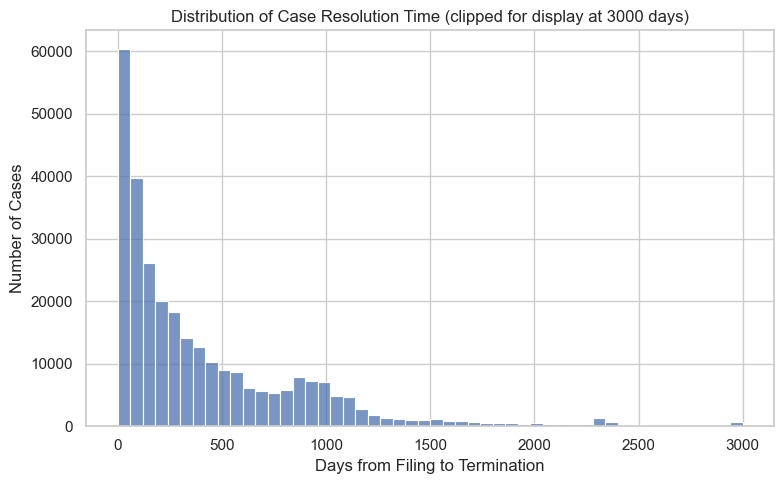

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df["RESOLUTION_DAYS"].clip(upper=3000), bins=50, ax=ax, color="#4C72B0")
ax.set_title("Distribution of Case Resolution Time (clipped for display at 3000 days)")
ax.set_xlabel("Days from Filing to Termination")
ax.set_ylabel("Number of Cases")
plt.tight_layout()
plt.show()

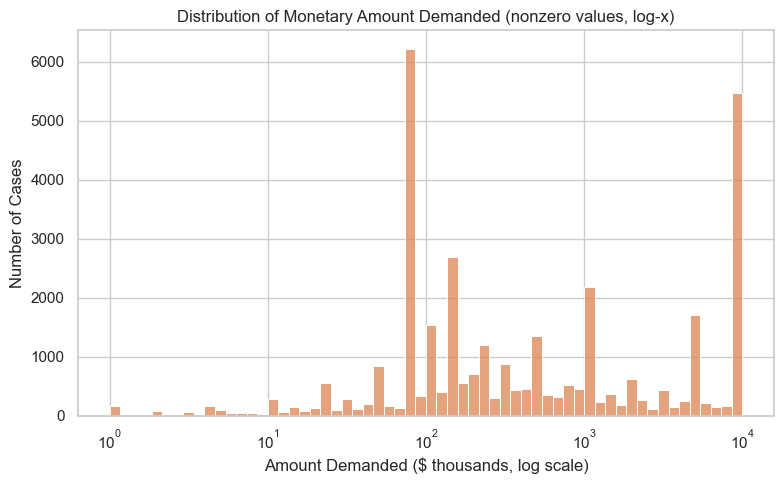

88.1% of cases record $0 demanded (no dollar figure entered).
5364 cases are top-coded at 9999 (codebook: true amount exceeds $10,000k).


In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(df.loc[df["DEMANDED"] > 0, "DEMANDED"], bins=60, log_scale=(True, False), ax=ax, color="#DD8452")
ax.set_title("Distribution of Monetary Amount Demanded (nonzero values, log-x)")
ax.set_xlabel("Amount Demanded ($ thousands, log scale)")
ax.set_ylabel("Number of Cases")
plt.tight_layout()
plt.show()

print(f"{(df['DEMANDED']==0).mean()*100:.1f}% of cases record $0 demanded (no dollar figure entered).")
print(f"{(df['DEMANDED']==9999).sum()} cases are top-coded at 9999 (codebook: true amount exceeds $10,000k).")

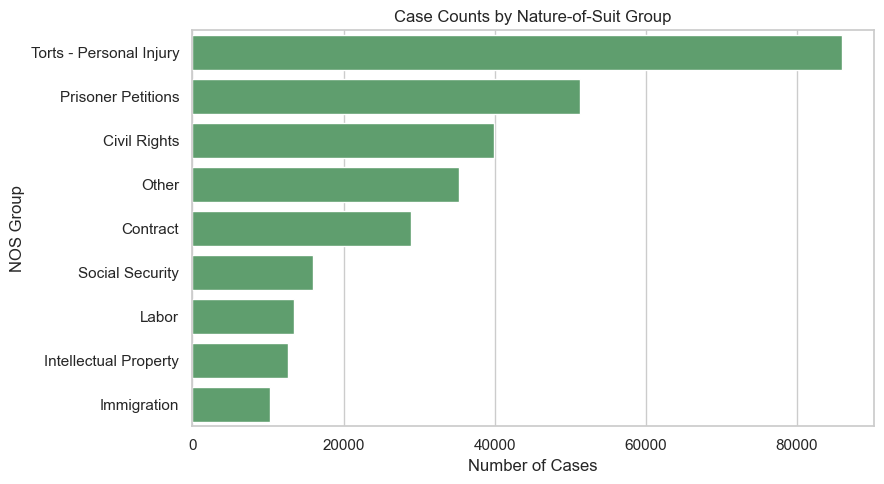

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
order = df["NOS_GROUP"].value_counts().index
sns.countplot(data=df, y="NOS_GROUP", order=order, ax=ax, color="#55A868")
ax.set_title("Case Counts by Nature-of-Suit Group")
ax.set_xlabel("Number of Cases")
ax.set_ylabel("NOS Group")
plt.tight_layout()
plt.show()

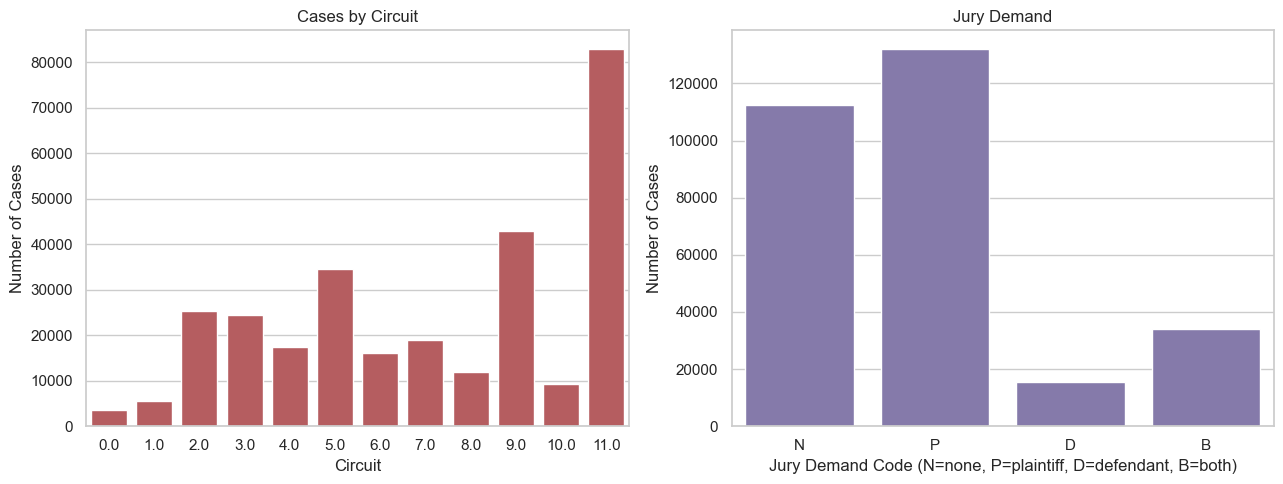

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x="CIRCUIT", ax=axes[0], color="#C44E52")
axes[0].set_title("Cases by Circuit")
axes[0].set_xlabel("Circuit"); axes[0].set_ylabel("Number of Cases")

sns.countplot(data=df, x="JURY", order=["N","P","D","B"], ax=axes[1], color="#8172B2")
axes[1].set_title("Jury Demand")
axes[1].set_xlabel("Jury Demand Code (N=none, P=plaintiff, D=defendant, B=both)")
axes[1].set_ylabel("Number of Cases")
plt.tight_layout()
plt.show()

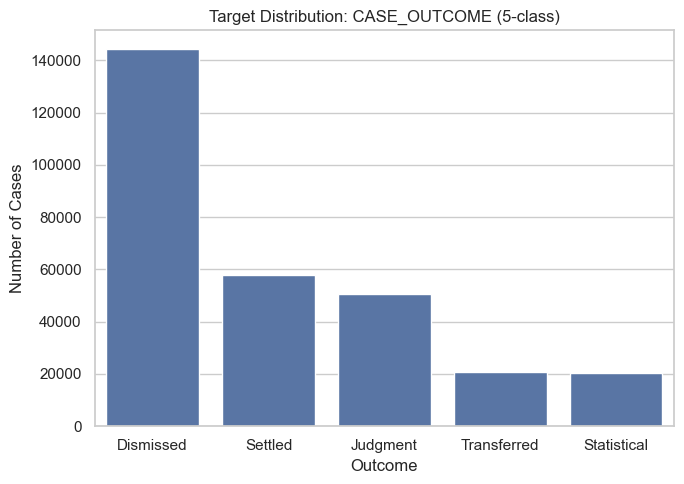

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=df, x="CASE_OUTCOME",
              order=df["CASE_OUTCOME"].value_counts().index, ax=ax, color="#4C72B0")
ax.set_title("Target Distribution: CASE_OUTCOME (5-class)")
ax.set_xlabel("Outcome"); ax.set_ylabel("Number of Cases")
plt.tight_layout()
plt.show()

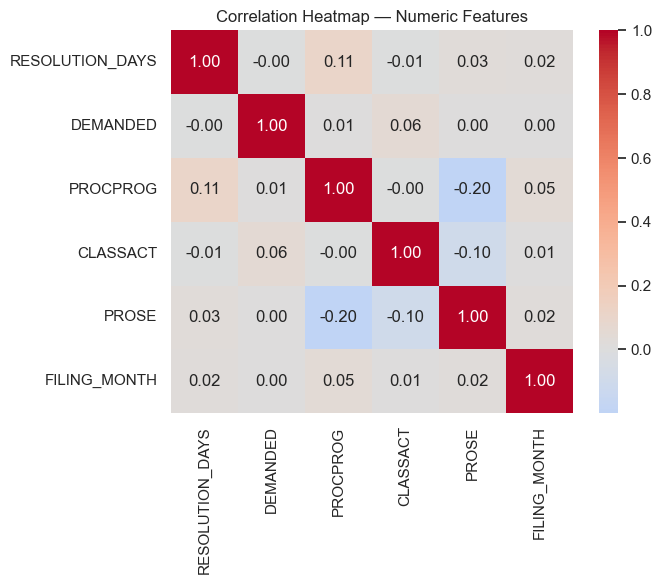

In [15]:
numeric_for_corr = df[["RESOLUTION_DAYS", "DEMANDED", "PROCPROG", "CLASSACT", "PROSE"]].copy()
numeric_for_corr["CLASSACT"] = numeric_for_corr["CLASSACT"].replace(-8, 0)  # sentinel -> "not a class action"
numeric_for_corr["FILING_MONTH"] = df["FILEDATE"].dt.month

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(numeric_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap — Numeric Features")
plt.tight_layout()
plt.show()

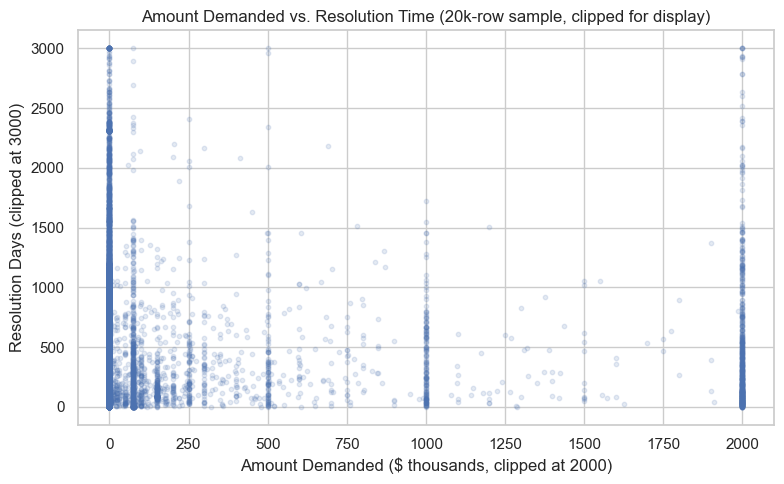

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
sample = df.sample(20000, random_state=RANDOM_STATE)  # subsample for a readable scatter on 293k rows
ax.scatter(sample["DEMANDED"].clip(upper=2000), sample["RESOLUTION_DAYS"].clip(upper=3000),
           alpha=0.15, s=10, color="#4C72B0")
ax.set_title("Amount Demanded vs. Resolution Time (20k-row sample, clipped for display)")
ax.set_xlabel("Amount Demanded ($ thousands, clipped at 2000)")
ax.set_ylabel("Resolution Days (clipped at 3000)")
plt.tight_layout()
plt.show()

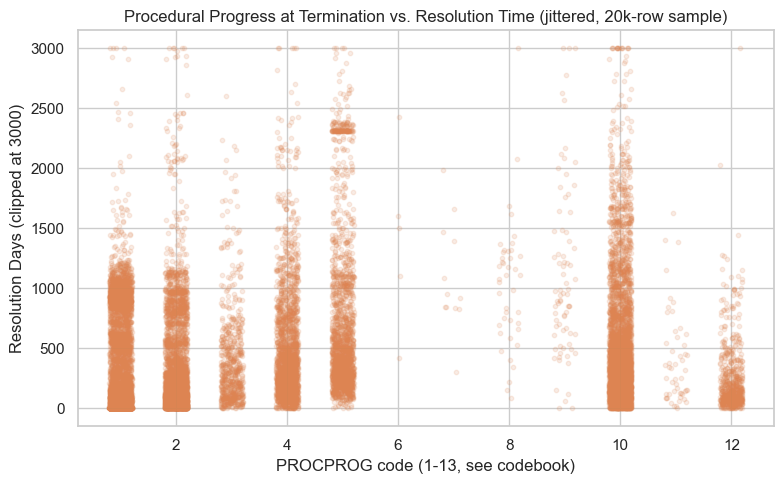

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
sample2 = df.sample(20000, random_state=RANDOM_STATE)
ax.scatter(sample2["PROCPROG"] + np.random.uniform(-0.2, 0.2, size=len(sample2)),  # jitter for visibility
           sample2["RESOLUTION_DAYS"].clip(upper=3000), alpha=0.15, s=10, color="#DD8452")
ax.set_title("Procedural Progress at Termination vs. Resolution Time (jittered, 20k-row sample)")
ax.set_xlabel("PROCPROG code (1-13, see codebook)")
ax.set_ylabel("Resolution Days (clipped at 3000)")
plt.tight_layout()
plt.show()

# Preprocessing & Feature Engineering

**Data cleaning**

In [18]:
drop_cols = [
    "DOCKET", "PLT", "DEF",
    "TITL", "SECTION", "SUBSECT",
    "FILEJUDG", "FILEMAG", "TERMJUDG", "TERMMAG",
    "TRANSDAT", "TRANSOFF", "TRANSDOC", "TRANSORG",
    "DJOINED", "PRETRIAL", "TRIBEGAN", "TRIALEND",
    "TAPEYEAR", "STATUSCD",
    "TRCLACT",
    "AMTREC",
    "TERMDATE", "TDATEUSE", "FDATEUSE",
    "MDLDOCK", "ARBIT", "TRMARB",
    "COUNTY",
    "NOJ", "JUDGMENT",
    "OFFICE",
]

df_clean = df.drop(columns=drop_cols)
print("Columns dropped:", len(drop_cols))
print("Remaining columns:", df_clean.shape[1], "-> ", list(df_clean.columns))

Columns dropped: 32
Remaining columns: 17 ->  ['CIRCUIT', 'DISTRICT', 'ORIGIN', 'FILEDATE', 'JURIS', 'NOS', 'RESIDENC', 'JURY', 'CLASSACT', 'DEMANDED', 'PROCPROG', 'DISP', 'PROSE', 'IFP', 'RESOLUTION_DAYS', 'CASE_OUTCOME', 'NOS_GROUP']


Removing Duplicated rows.

In [19]:
n_dupes = df_clean.duplicated().sum()
print(f"Fully duplicated rows: {n_dupes}")
if n_dupes > 0:
    df_clean = df_clean.drop_duplicates()
    print("Duplicates removed. New shape:", df_clean.shape)
else:
    print("No duplicate rows found -> nothing to drop.")

Fully duplicated rows: 50078
Duplicates removed. New shape: (243599, 17)


Converting -8 values (not-applicable) 0 to avoid mis-calculations in mean and numerical values in place of categorical features.

In [20]:
df_clean["IS_DIVERSITY_CASE"] = (df_clean["JURIS"] == 4).astype(int)
df_clean["RESIDENC"] = df_clean["RESIDENC"].replace(-8, 0)
df_clean["CLASSACT"] = df_clean["CLASSACT"].replace(-8, 0)
df_clean["IFP_FLAG"] = (df_clean["IFP"].astype(str) == "FP").astype(int)
df_clean = df_clean.drop(columns=["IFP"])  # superseded by IFP_FLAG

print(df_clean[["RESIDENC", "CLASSACT", "IFP_FLAG", "IS_DIVERSITY_CASE"]].describe())

            RESIDENC       CLASSACT       IFP_FLAG  IS_DIVERSITY_CASE
count  243599.000000  243599.000000  243599.000000      243599.000000
mean        6.416685       0.037262       0.145838           0.281134
std        11.964466       0.189404       0.352944           0.449554
min         0.000000       0.000000       0.000000           0.000000
25%         0.000000       0.000000       0.000000           0.000000
50%         0.000000       0.000000       0.000000           0.000000
75%        12.000000       0.000000       0.000000           1.000000
max        66.000000       1.000000       1.000000           1.000000


Handling Outliers

In [21]:
cap_value = df_clean["RESOLUTION_DAYS"].quantile(0.99)
df_clean["RESOLUTION_DAYS_CAPPED"] = df_clean["RESOLUTION_DAYS"].clip(upper=cap_value)

print(f"99th percentile cap: {cap_value:.0f} days (~{cap_value/365:.1f} years)")
print(f"Rows affected by capping: {(df_clean['RESOLUTION_DAYS'] > cap_value).sum()} "
      f"({(df_clean['RESOLUTION_DAYS'] > cap_value).mean()*100:.2f}%)")
df_clean[["RESOLUTION_DAYS", "RESOLUTION_DAYS_CAPPED"]].describe()

99th percentile cap: 2158 days (~5.9 years)
Rows affected by capping: 2434 (1.00%)


,RESOLUTION_DAYS,RESOLUTION_DAYS_CAPPED
count,243599.000000,243599.000000
mean,383.995731,377.884232
std,463.798935,426.765424
min,0.000000,0.000000
25%,83.000000,83.000000
50%,222.000000,222.000000
75%,510.000000,510.000000
max,18915.000000,2158.000000


**Feature Engineering**

In [22]:
df_clean["FILING_MONTH"] = df_clean["FILEDATE"].dt.month
df_clean["FILING_QUARTER"] = df_clean["FILEDATE"].dt.quarter
df_clean["HIGH_STAKES"] = (df_clean["DEMANDED"] >= 100).astype(int)  # DEMANDED is in $ thousands -> >=$100k

print(f"HIGH_STAKES == 1 for {df_clean['HIGH_STAKES'].mean()*100:.1f}% of cases")
print(f"IS_DIVERSITY_CASE == 1 for {df_clean['IS_DIVERSITY_CASE'].mean()*100:.1f}% of cases (built in B1)")
df_clean[["FILING_MONTH", "FILING_QUARTER", "HIGH_STAKES", "IS_DIVERSITY_CASE"]].head()

HIGH_STAKES == 1 for 9.9% of cases
IS_DIVERSITY_CASE == 1 for 28.1% of cases (built in B1)


,FILING_MONTH,FILING_QUARTER,HIGH_STAKES,IS_DIVERSITY_CASE
0,7,3,0,0
1,7,3,0,0
2,11,4,0,0
3,9,3,0,1
4,2,1,0,1


Splitting categorical and numerical features

In [23]:
categorical_cols = ["CIRCUIT", "DISTRICT", "ORIGIN", "JURIS", "NOS_GROUP", "JURY"]
numeric_cols = ["DEMANDED", "RESIDENC", "CLASSACT", "PROSE", "IFP_FLAG",
                "IS_DIVERSITY_CASE", "PROCPROG",
                "FILING_MONTH", "FILING_QUARTER", "HIGH_STAKES"]

feature_cols = categorical_cols + numeric_cols
X = df_clean[feature_cols].copy()
y_reg = df_clean["RESOLUTION_DAYS_CAPPED"]
y_clf = df_clean["CASE_OUTCOME"]

print("Feature matrix shape:", X.shape)
X.head()

Feature matrix shape: (243599, 16)


,CIRCUIT,DISTRICT,ORIGIN,JURIS,NOS_GROUP,JURY,DEMANDED,RESIDENC,CLASSACT,PROSE,IFP_FLAG,IS_DIVERSITY_CASE,PROCPROG,FILING_MONTH,FILING_QUARTER,HIGH_STAKES
0,0.0,90,4.0,3.0,Other,P,0.0,0.0,0.0,0.0,0,0,10.0,7,3,0
1,0.0,90,1.0,3.0,Civil Rights,P,0.0,0.0,0.0,0.0,0,0,4.0,7,3,0
2,0.0,90,1.0,3.0,Prisoner Petitions,N,0.0,0.0,0.0,0.0,0,0,10.0,11,4,0
3,0.0,90,8.0,4.0,Contract,N,0.0,55.0,0.0,0.0,0,1,10.0,9,3,0
4,0.0,90,4.0,4.0,Contract,P,0.0,24.0,0.0,0.0,0,1,10.0,2,1,0


In [24]:
# Stratified split on the CLASSIFICATION target, per rubric requirement.
X_train, X_test, y_clf_train, y_clf_test = train_test_split(
    X, y_clf, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf
)

y_reg_train = y_reg.loc[X_train.index]
y_reg_test = y_reg.loc[X_test.index]

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("\nClass balance preserved after stratified split:")
print(pd.concat([
    y_clf_train.value_counts(normalize=True).rename("train"),
    y_clf_test.value_counts(normalize=True).rename("test"),
], axis=1).round(3))

Train shape: (194879, 16)  Test shape: (48720, 16)

Class balance preserved after stratified split:
              train   test
CASE_OUTCOME              
Dismissed     0.469  0.469
Settled       0.221  0.221
Judgment      0.197  0.197
Transferred   0.082  0.082
Statistical   0.030  0.030


Feature Scaling

In [25]:
# Fit the scaler on TRAIN ONLY, then transform both -> prevents test-set
# information (mean/std) from leaking into preprocessing.
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train_scaled[numeric_cols].describe().round(2)

,DEMANDED,RESIDENC,CLASSACT,PROSE,IFP_FLAG,IS_DIVERSITY_CASE,PROCPROG,FILING_MONTH,FILING_QUARTER,HIGH_STAKES
count,194879.00,194879.00,194879.0,194879.00,194879.00,194879.00,194879.00,194879.00,194879.00,194879.00
mean,-0.00,-0.00,-0.0,0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00
std,1.00,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-0.20,-0.54,-0.2,-0.64,-0.41,-0.63,-1.03,-1.62,-1.35,-0.33
25%,-0.20,-0.54,-0.2,-0.64,-0.41,-0.63,-0.77,-0.73,-0.44,-0.33
50%,-0.20,-0.54,-0.2,-0.64,-0.41,-0.63,-0.23,-0.14,-0.44,-0.33
75%,-0.20,0.47,-0.2,1.18,-0.41,1.60,1.36,0.74,0.46,-0.33
max,6.18,5.00,5.1,4.83,2.42,1.60,2.16,1.63,1.37,3.02


In [26]:
# Fit the encoder on TRAIN ONLY; handle_unknown='ignore' protects against any
# category seen at test time but absent from the training split.
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[categorical_cols])

train_encoded = pd.DataFrame(
    encoder.transform(X_train[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index,
)
test_encoded = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index,
)

X_train_encoded = pd.concat([X_train_scaled[numeric_cols], train_encoded], axis=1)
X_test_encoded = pd.concat([X_test_scaled[numeric_cols], test_encoded], axis=1)

print("Encoded training feature matrix (pre-PCA):", X_train_encoded.shape)
print("Encoded test feature matrix (pre-PCA):", X_test_encoded.shape)

Encoded training feature matrix (pre-PCA): (194879, 146)
Encoded test feature matrix (pre-PCA): (48720, 146)


**PCA**

Original encoded feature count: 146
Components needed for 95% variance: 37


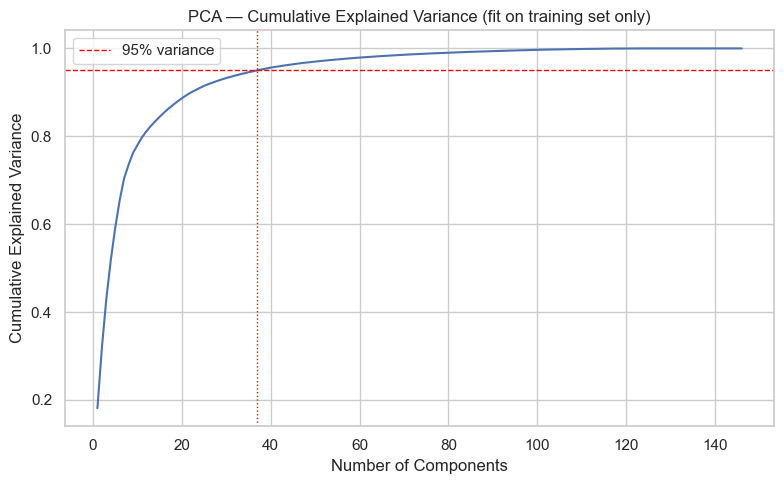

In [27]:
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_encoded)

cum_var = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = int(np.argmax(cum_var >= 0.95) + 1)

print(f"Original encoded feature count: {X_train_encoded.shape[1]}")
print(f"Components needed for 95% variance: {n_components_95}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(range(1, len(cum_var) + 1), cum_var, color="#4C72B0")
ax.axhline(0.95, color="red", linestyle="--", linewidth=1, label="95% variance")
ax.axvline(n_components_95, color="red", linestyle=":", linewidth=1)
ax.set_title("PCA — Cumulative Explained Variance (fit on training set only)")
ax.set_xlabel("Number of Components")
ax.set_ylabel("Cumulative Explained Variance")
ax.legend()
plt.tight_layout()
plt.show()

In [28]:
pca = PCA(n_components=n_components_95, random_state=RANDOM_STATE)

X_train_pca_arr = pca.fit_transform(X_train_encoded)
X_test_pca_arr = pca.transform(X_test_encoded)

pc_columns = [f"PC{i+1}" for i in range(n_components_95)]

# These are now THE feature matrices used by every model in Section C and Section D.
X_train_final = pd.DataFrame(X_train_pca_arr, columns=pc_columns, index=X_train_encoded.index)
X_test_final = pd.DataFrame(X_test_pca_arr, columns=pc_columns, index=X_test_encoded.index)

print("Modelling feature matrix (post-PCA) -- train:", X_train_final.shape, " test:", X_test_final.shape)
print(f"Variance retained: {pca.explained_variance_ratio_.sum()*100:.1f}%")
X_train_final.head()

Modelling feature matrix (post-PCA) -- train: (194879, 37)  test: (48720, 37)
Variance retained: 95.0%


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,PC26,PC27,PC28,PC29,PC30,PC31,PC32,PC33,PC34,PC35,PC36,PC37
257089,-1.323546,0.417784,-0.137905,0.778758,-0.737081,-0.573565,0.880086,0.467569,-0.075362,0.069189,0.053028,-0.725293,0.466976,-0.352407,0.271333,0.408770,-0.035676,-0.008646,-0.347200,0.362429,-0.117449,-0.009215,-0.001517,0.248791,0.012816,0.050544,0.268181,-0.040458,0.085042,-0.177859,0.106896,0.068642,-0.422857,0.464063,-0.212948,0.031299,0.075438
191771,-0.524889,-2.068487,-0.423453,-0.931001,0.182275,-0.590996,0.005794,-0.524323,0.269210,-0.422658,-0.787966,0.342231,0.842456,0.701871,0.157822,-0.024928,0.100360,-0.076491,-0.012318,-0.576412,-0.387345,-0.110806,-0.106596,0.208939,-0.271025,-0.368938,-0.616128,0.120878,0.135523,-0.099954,0.168040,-0.599826,0.003401,0.291751,0.015664,0.021551,-0.037138
280751,2.286819,1.727245,-0.868488,-0.116135,1.137219,0.403575,0.403448,-0.089827,0.399924,-1.025404,-0.032100,-0.409292,0.316233,-0.165489,-0.050643,0.332292,0.059566,0.110739,-0.141819,0.499749,0.140766,-0.039845,0.008696,0.024190,1.119970,0.058660,0.332784,-0.033625,-0.142729,0.010879,0.115358,-0.330418,0.504635,-0.212904,0.201280,0.059632,0.048155
107923,-0.097016,0.604366,2.132738,-0.641064,-0.431144,-1.251381,-0.786778,-0.775817,-1.825230,-0.503830,0.801697,0.164354,-0.889040,0.413011,-0.082736,0.648527,0.230407,-0.615338,0.054708,-0.711474,-0.346129,-0.067061,-0.026886,0.477265,0.098221,0.038780,0.076813,0.181475,0.158875,-0.087911,0.050262,-0.050669,-0.011576,-0.171564,-0.009007,0.050538,-0.094960
93531,-1.228696,-0.427548,-0.183927,0.885343,-0.818007,-0.660922,0.380290,1.203819,-0.240557,-0.227290,0.135382,0.129613,-0.861557,-0.196242,0.245917,0.390275,-0.023054,-0.160186,-0.090481,-0.516567,-0.372472,-0.091024,0.034766,0.385862,0.025299,0.045904,0.146534,0.093127,0.113473,-0.105587,0.095829,-0.011797,0.030659,-0.137621,-0.004192,-0.008273,-0.039565


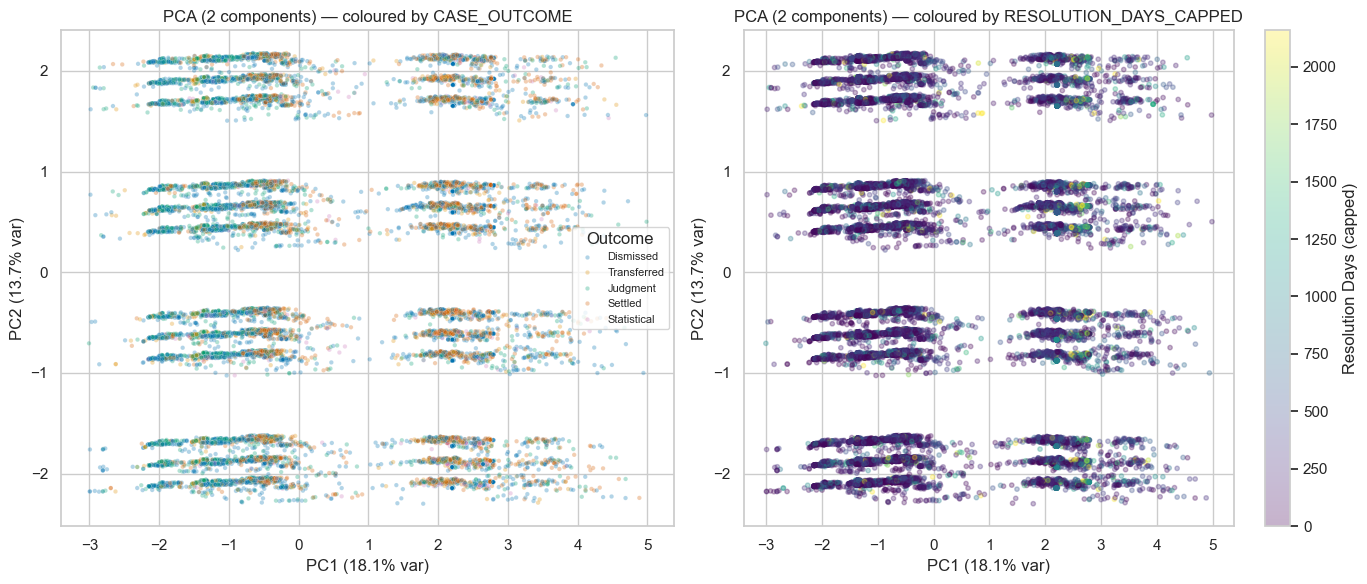

In [29]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca2d = pca_2d.fit_transform(X_train_encoded)

sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(X_train_pca2d), size=20000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(x=X_train_pca2d[sample_idx, 0], y=X_train_pca2d[sample_idx, 1],
                 hue=y_clf_train.iloc[sample_idx].values, palette="colorblind",
                 alpha=0.3, s=10, ax=axes[0])
axes[0].set_title("PCA (2 components) — coloured by CASE_OUTCOME")
axes[0].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% var)")
axes[0].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% var)")
axes[0].legend(title="Outcome", fontsize=8)

sc = axes[1].scatter(X_train_pca2d[sample_idx, 0], X_train_pca2d[sample_idx, 1],
                      c=y_reg_train.iloc[sample_idx].values, cmap="viridis", alpha=0.3, s=10)
axes[1].set_title("PCA (2 components) — coloured by RESOLUTION_DAYS_CAPPED")
axes[1].set_xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% var)")
axes[1].set_ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% var)")
plt.colorbar(sc, ax=axes[1], label="Resolution Days (capped)")

plt.tight_layout()
plt.show()

In [30]:
print("Final cleaned dataframe ready for Section C/D modelling:")
print("Shape:", df_clean.shape)
df_clean.head()

Final cleaned dataframe ready for Section C/D modelling:
Shape: (243599, 22)


,CIRCUIT,DISTRICT,ORIGIN,FILEDATE,JURIS,NOS,RESIDENC,JURY,CLASSACT,DEMANDED,PROCPROG,DISP,PROSE,RESOLUTION_DAYS,CASE_OUTCOME,NOS_GROUP,IS_DIVERSITY_CASE,IFP_FLAG,RESOLUTION_DAYS_CAPPED,FILING_MONTH,FILING_QUARTER,HIGH_STAKES
0,0.0,90,4.0,2013-07-29,3.0,890.0,0.0,P,0.0,0.0,10.0,13.0,0.0,3577,Settled,Other,0,0,2158,7,3,0
1,0.0,90,1.0,2001-07-11,3.0,442.0,0.0,P,0.0,0.0,4.0,12.0,0.0,7820,Dismissed,Civil Rights,0,0,2158,7,3,0
2,0.0,90,1.0,2004-11-17,3.0,530.0,0.0,N,0.0,0.0,10.0,14.0,0.0,6749,Dismissed,Prisoner Petitions,0,0,2158,11,4,0
3,0.0,90,8.0,2007-09-20,4.0,110.0,55.0,N,0.0,0.0,10.0,13.0,0.0,5618,Settled,Contract,1,0,2158,9,3,0
4,0.0,90,4.0,2022-02-07,4.0,190.0,24.0,P,0.0,0.0,10.0,14.0,0.0,450,Dismissed,Contract,1,0,450,2,1,0


---
### Save processed artifacts for downstream notebooks

In [31]:
import joblib
import os

os.makedirs("../data/processed", exist_ok=True)

joblib.dump({
    "X_train_final": X_train_final,
    "X_test_final": X_test_final,
    "y_reg_train": y_reg_train,
    "y_reg_test": y_reg_test,
    "y_clf_train": y_clf_train,
    "y_clf_test": y_clf_test,
    "numeric_cols": numeric_cols,
    "RANDOM_STATE": RANDOM_STATE,
}, "../data/processed/model_ready_data.pkl")

print("Saved preprocessed train/test artifacts to data/processed/model_ready_data.pkl")
print("X_train_final shape:", X_train_final.shape, " X_test_final shape:", X_test_final.shape)

Saved preprocessed train/test artifacts to data/processed/model_ready_data.pkl
X_train_final shape: (194879, 37)  X_test_final shape: (48720, 37)
